
### Phạm vi phần việc
| Hạng mục | Nội dung |
|---|---|
| Bài 7 – Task 5 | Simulated Annealing với 2 lịch làm nguội (`sa_geometric`, `sa_linear`) |
| Bài 8 – Task 6 (phần SA) | ≥ 100 lượt tại n = 4 và n = 8; hội tụ tại n = 8; thời gian theo n ∈ {4, 8, 12, 16, 20} |
| Bài 8 – Nâng cao | So sánh 4 toán tử di chuyển cục bộ với Efficient Stochastic HC |
| Sản phẩm | `results_sa.csv`, `history_sa.csv`, `timing_sa.csv`, `plot_all.py`, các biểu đồ |

### Môi trường chạy

In [1]:
import sys, math, time, platform, os
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | matplotlib 3.10.8


## 1. Hàm dùng chung (lấy từ notebook đề bài)

`conflicts(board)` là hàm mục tiêu $h(\mathbf q)$ = số cặp quân hậu cùng hàng hoặc cùng đường chéo (mỗi cột đúng một quân nên không bao giờ có xung đột cột). `h = 0` khi và chỉ khi không có cặp quân hậu nào tấn công nhau.

`make_board(n, seed)` là hàm **thêm vào** để cố định bàn cờ khởi tạo theo seed: lượt thứ *k* dùng `seed = k`. Cả nhóm dùng chung hàm này để các thuật toán được so sánh trên **cùng một tập bàn cờ ban đầu**.

In [2]:
def conflicts(board):
    """Hàm mục tiêu h: số cặp quân hậu xung đột (cùng hàng/đường chéo)."""
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(c * (c - 1) // 2 for c in horizontal_cnt + diagonal1_cnt + diagonal2_cnt)

def make_board(n, seed):
    """Bàn cờ ngẫu nhiên tái lập được: lượt k dùng seed = k."""
    return np.random.default_rng(seed).integers(0, n, size=n)

def show_board(board, cols=("white", "gray"), fontsize=36, ax=None, title=None):
    n = len(board)
    disp = np.fromfunction(lambda i, j: (i + j) % 2, (n, n))
    show = ax is None
    if ax is None: fig, ax = plt.subplots(figsize=(3.2, 3.2))
    ax.imshow(disp, cmap=colors.ListedColormap(cols), norm=colors.BoundaryNorm(range(3), 2))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for j in range(n):
        ax.text(j, board[j], "\u265B", fontsize=fontsize, ha="center", va="center", color="firebrick")
    ax.set_title(title or f"h = {conflicts(board)}")
    if show: plt.show()

## 2. Task 5 – Simulated Annealing

### 2.1 Thiết kế thuật toán
* **Trạng thái:** vector `board` (mỗi cột một quân hậu). **Láng giềng:** chọn ngẫu nhiên một cột và chuyển quân hậu sang một hàng *khác* (đúng "local improvement move" của đề).
* **Chấp nhận:** đặt $\Delta h = h_{mới} - h_{hiện tại}$. Nếu $\Delta h \le 0$ thì chấp nhận; nếu $\Delta h > 0$ thì chấp nhận với xác suất $p = e^{-\Delta h / T}$.
* **Hai lịch làm nguội** (k là số vòng lặp, `max_iter` là số vòng tối đa):
  * *Hình học* (`sa_geometric`): $T_k = T_0\,\alpha^{k}$, với $\alpha$ chọn sao cho nhiệt độ cuối bằng $T_{end}=0.01$.
  * *Tuyến tính* (`sa_linear`): $T_k = T_0\,(1 - k/\text{max\_iter})$.
* **Điều kiện dừng:** dừng khi $h = 0$ (**thành công**) hoặc hết `max_iter = 1000·n` vòng lặp. Khi hết vòng lặp mà $h>0$ thì lượt chạy **thất bại**, nhưng vẫn trả về **nghiệm tốt nhất** đã gặp (h nhỏ nhất).
* **Phân biệt:** *thành công* = `h_cuoi == 0`; *nghiệm tốt nhất* = bàn cờ có h nhỏ nhất trong cả lượt chạy (có thể $>0$).
* **Số lần đánh giá:** 1 (bàn cờ đầu) + 1 cho mỗi láng giềng được sinh.
* Hàm trả về đúng hợp đồng chung: `(board_cuoi, h_cuoi, so_buoc, so_lan_danh_gia)`; khi `record=True` trả thêm lịch sử h.
* **Tham số** được chọn sau khi thử nhanh trên n = 8 và n = 20 (mục 2.3): hình học dùng $T_0 = 2$, tuyến tính dùng $T_0 = 0.5$.

In [3]:
def temperature(schedule, k, max_iter, T0, alpha):
    if schedule == "geometric":
        return T0 * alpha ** k
    return T0 * (1 - k / max_iter)          # linear

def simulated_annealing(board, seed, schedule="geometric", T0=2.0, T_end=0.01,
                        max_iter=None, record=False):
    """Simulated Annealing cho n-Queens.
    Trả về (board_tốt_nhất, h_cuối, số_bước, số_lần_đánh_giá[, lịch_sử_h])."""
    n = len(board)
    rng = np.random.default_rng(seed + 10_000)      # RNG của thuật toán, tách khỏi RNG bàn cờ
    if max_iter is None: max_iter = 1000 * n
    alpha = (T_end / T0) ** (1 / max_iter)          # chỉ dùng cho lịch hình học
    cur = np.array(board, dtype=int)
    h = conflicts(cur); evals = 1
    best, best_h = cur.copy(), h
    hist = [h]
    k = 0
    while k < max_iter and h > 0:
        T = max(temperature(schedule, k, max_iter, T0, alpha), 1e-9)
        col = rng.integers(n)                       # chọn cột ngẫu nhiên
        row = rng.integers(n - 1)                   # hàng mới khác hàng cũ
        if row >= cur[col]: row += 1
        old = cur[col]; cur[col] = row
        h_new = conflicts(cur); evals += 1
        dh = h_new - h
        if dh <= 0 or rng.random() < math.exp(-dh / T):   # tiêu chí Metropolis
            h = h_new
            if h < best_h: best, best_h = cur.copy(), h
        else:
            cur[col] = old                          # từ chối: hoàn tác
        k += 1
        hist.append(h)
    out = (best, best_h, k, evals)
    return out + (hist,) if record else out

SCHEDULES = {"sa_geometric": dict(schedule="geometric", T0=2.0),
             "sa_linear":    dict(schedule="linear",    T0=0.5)}

def solve(board, seed, name="sa_geometric"):
    """Hợp đồng chung: solve(board, seed) -> (board_cuoi, h_cuoi, so_buoc, so_lan_danh_gia)."""
    return simulated_annealing(board, seed, **SCHEDULES[name])

### 2.2 Ví dụ một lượt chạy (n = 8, seed = 0)

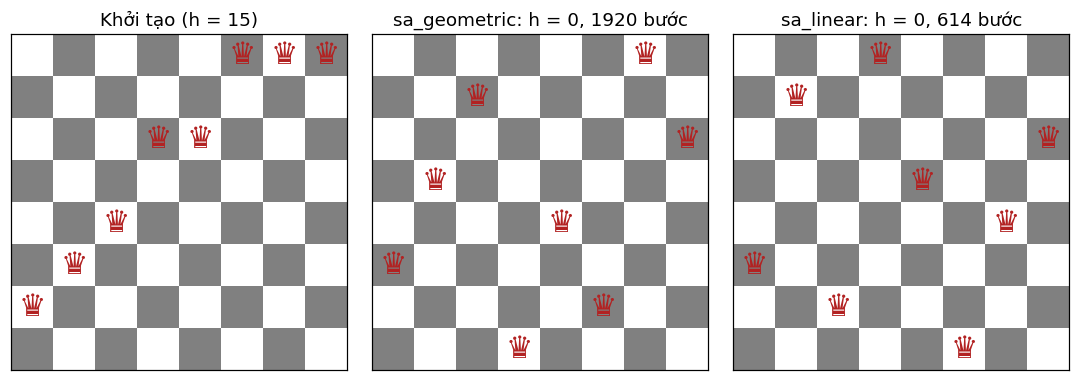

In [4]:
b0 = make_board(8, 0)
res = {name: solve(b0, 0, name) for name in SCHEDULES}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
show_board(b0, ax=axes[0], fontsize=20, title=f"Khởi tạo (h = {conflicts(b0)})")
for ax, (name, r) in zip(axes[1:], res.items()):
    show_board(r[0], ax=ax, fontsize=20, title=f"{name}: h = {r[1]}, {r[2]} bước")
plt.tight_layout(); plt.savefig("figures/board_sa.png", bbox_inches="tight"); plt.show()
assert all(conflicts(r[0]) == r[1] for r in res.values())   # kiểm tra h_cuoi khớp bàn cờ trả về

### 2.3 Trực quan hóa quá trình tìm kiếm và thử nghiệm lịch làm nguội

Biểu đồ dưới vẽ h theo vòng lặp (n = 8, seed = 0) cho các giá trị $T_0$ khác nhau. Để thấy rõ cả giai đoạn "nóng" lẫn giai đoạn "nguội", ta vẽ cả khi thuật toán **không dừng sớm** bằng cách chạy một biến thể với `h` không dừng ở 0 (chỉ phục vụ minh họa, đặt `stop_at_zero=False`).

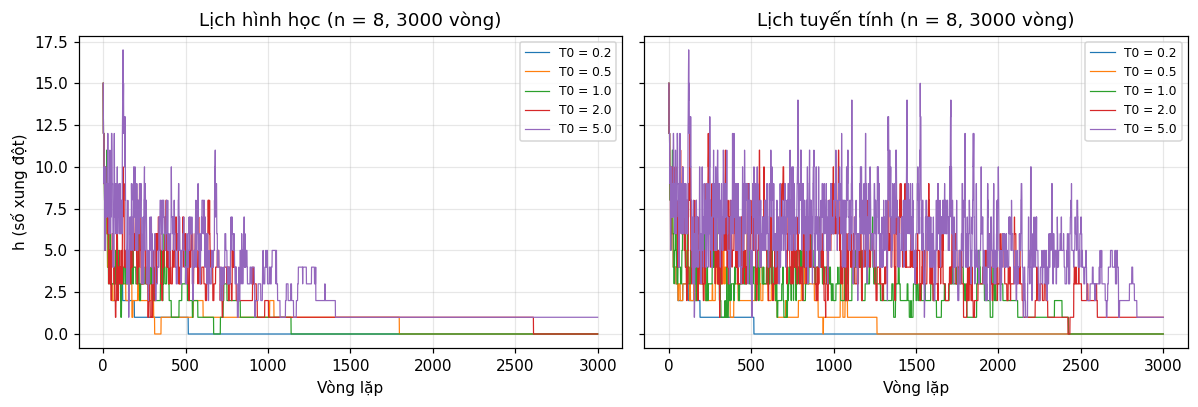

In [5]:
def sa_trace(n, seed, schedule, T0, max_iter=None):
    """Phiên bản minh họa: KHÔNG dừng khi h = 0 để thấy toàn bộ lịch nhiệt độ."""
    max_iter = max_iter or 1000 * n
    rng = np.random.default_rng(seed + 10_000)
    alpha = (0.01 / T0) ** (1 / max_iter)
    cur = make_board(n, seed).copy(); h = conflicts(cur); hs = [h]; ok_first = None
    for k in range(max_iter):
        T = max(temperature(schedule, k, max_iter, T0, alpha), 1e-9)
        col = rng.integers(n); row = rng.integers(n - 1)
        if row >= cur[col]: row += 1
        old = cur[col]; cur[col] = row
        hn = conflicts(cur); dh = hn - h
        if dh <= 0 or rng.random() < math.exp(-dh / T): h = hn
        else: cur[col] = old
        hs.append(h)
    return np.array(hs)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, sched in zip(axes, ["geometric", "linear"]):
    for T0 in (0.2, 0.5, 1.0, 2.0, 5.0):
        ax.plot(sa_trace(8, 0, sched, T0, 3000), lw=.8, label=f"T0 = {T0}")
    ax.set_title(f"Lịch {'hình học' if sched=='geometric' else 'tuyến tính'} (n = 8, 3000 vòng)")
    ax.set_xlabel("Vòng lặp"); ax.legend(fontsize=8)
axes[0].set_ylabel("h (số xung đột)")
plt.tight_layout(); plt.savefig("figures/sa_schedule_trace.png", bbox_inches="tight"); plt.show()

Thử định lượng ảnh hưởng của $T_0$ (n = 8 và n = 20, 20 lượt, `max_iter = 500·n`) — đây là bước chọn tham số đã nêu ở mục 2.1:

In [6]:
rows = []
for n in (8, 20):
    for sched in ("geometric", "linear"):
        for T0 in (0.5, 1.0, 2.0):
            ok, tm = 0, 0
            for s in range(20):
                t = time.perf_counter()
                _, hb, *_ = simulated_annealing(make_board(n, s), s, sched, T0=T0, max_iter=500 * n)
                tm += time.perf_counter() - t; ok += hb == 0
            rows.append(dict(n=n, lich=sched, T0=T0, ty_le_thanh_cong=ok / 20, tg_tb_ms=1000 * tm / 20))
tune = pd.DataFrame(rows)
print(tune.pivot_table(index=["n", "lich"], columns="T0", values="ty_le_thanh_cong").round(2).to_string())

T0            0.5   1.0   2.0
n  lich                      
8  geometric  1.0  1.00  1.00
   linear     1.0  1.00  1.00
20 geometric  0.7  0.75  0.90
   linear     0.7  0.40  0.05


**Nhận xét.** Tại n = 8 mọi cấu hình đều đạt 100%, nên n = 8 không phân biệt được các tham số. Tại n = 20 (ngân sách 10 000 vòng), hai lịch phản ứng **ngược nhau** với $T_0$:
* *Hình học:* tỷ lệ thành công tăng theo $T_0$ (70% → 75% → 90%). Nhiệt độ giảm theo hàm mũ nên dù bắt đầu rất nóng, thuật toán nhanh chóng đi vào vùng nhiệt độ hữu ích (T ≈ 0.1–0.5) và phần "nóng" chỉ tốn ít vòng lặp.
* *Tuyến tính:* tỷ lệ thành công **giảm** khi $T_0$ tăng (70% → 40% → 5%). Nhiệt độ giảm đều nên phần lớn vòng lặp nằm ở vùng quá nóng, nơi các nước đi tệ hơn (Δh = 1, 2) vẫn bị chấp nhận với xác suất cao và thuật toán gần như đi ngẫu nhiên.

Vì vậy chọn **hình học $T_0=2$** và **tuyến tính $T_0=0.5$**. *Hạn chế:* mỗi ô chỉ 20 lượt (sai số cỡ ±10 điểm phần trăm) và 20 seed này (0–19) nằm trong tập seed 0–99 dùng ở mục 3, nên có thiên lệch nhẹ do chọn tham số trên dữ liệu đánh giá.

## 3. Task 6 (phần SA) – ≥ 100 lượt tại n = 4 và n = 8

Mỗi thiết lập chạy 100 lượt với `seed = 0…99` (seed *k* → bàn cờ `make_board(n, k)`). Ghi: thành công (h = 0), h cuối, số bước, số lần đánh giá, thời gian (`time.perf_counter`). Kết quả lưu vào `results_sa.csv` đúng định dạng chung.

In [7]:
def run_batch(name, n, seeds=range(100)):
    rows = []
    for s in seeds:
        b = make_board(n, s)
        t = time.perf_counter()
        bf, hf, steps, evals = solve(b, s, name)
        dt = time.perf_counter() - t
        assert conflicts(bf) == hf
        rows.append(dict(thuat_toan=name, n=n, seed=s, thanh_cong=int(hf == 0), h_cuoi=hf,
                         so_buoc=steps, so_danh_gia=evals, thoi_gian_s=dt))
    return rows

rows = []
for name in SCHEDULES:
    for n in (4, 8):
        rows += run_batch(name, n)
results = pd.DataFrame(rows)
results.to_csv("results_sa.csv", index=False)

summary = (results.groupby(["thuat_toan", "n"])
           .agg(so_luot=("seed", "count"), thanh_cong_pct=("thanh_cong", lambda x: 100 * x.mean()),
                h_cuoi_tb=("h_cuoi", "mean"), h_cuoi_max=("h_cuoi", "max"),
                so_buoc_tb=("so_buoc", "mean"), so_danh_gia_tb=("so_danh_gia", "mean"),
                thoi_gian_tb_s=("thoi_gian_s", "mean"), thoi_gian_std_s=("thoi_gian_s", "std"))
           .round(5).reset_index())
summary

,thuat_toan,n,so_luot,thanh_cong_pct,h_cuoi_tb,h_cuoi_max,so_buoc_tb,so_danh_gia_tb,thoi_gian_tb_s,thoi_gian_std_s
0,sa_geometric,4,100,100.0,0.0,0,86.91,87.91,0.00079,0.00061
1,sa_geometric,8,100,100.0,0.0,0,2248.82,2249.82,0.03151,0.01828
2,sa_linear,4,100,100.0,0.0,0,41.16,42.16,0.00040,0.00031
3,sa_linear,8,100,100.0,0.0,0,911.12,912.12,0.01179,0.01059


**Cách tính trung bình:** trung bình số học trên 100 lượt (cả lượt thành công và thất bại); `thanh_cong_pct` là phần trăm lượt có `h_cuoi = 0`. Tiêu chí dừng: `h = 0` hoặc `max_iter = 1000·n` vòng lặp.

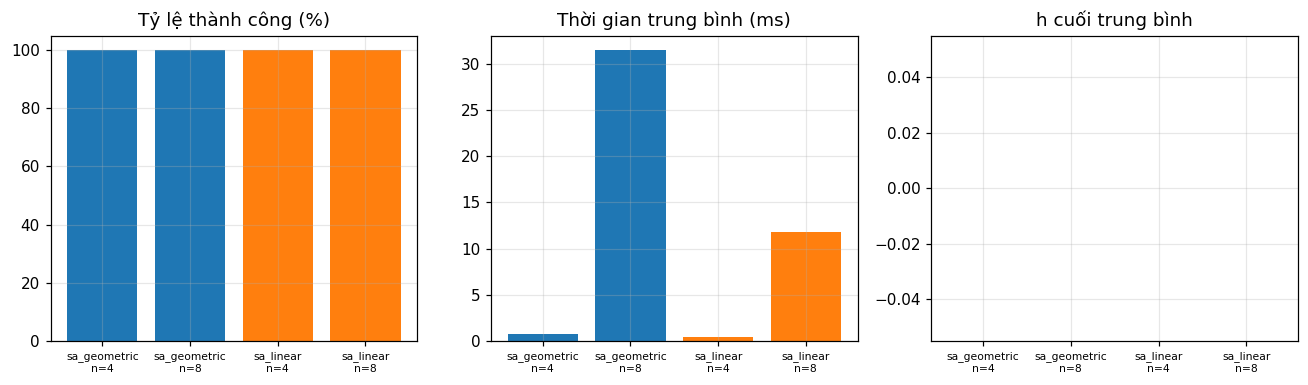

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
sub = summary.copy(); sub["nhan"] = sub.thuat_toan + "\nn=" + sub.n.astype(str)
cl = ["#1f77b4" if "geo" in a else "#ff7f0e" for a in sub.thuat_toan]
axes[0].bar(sub.nhan, sub.thanh_cong_pct, color=cl); axes[0].set_ylim(0, 105); axes[0].set_title("Tỷ lệ thành công (%)")
axes[1].bar(sub.nhan, sub.thoi_gian_tb_s * 1000, color=cl); axes[1].set_title("Thời gian trung bình (ms)")
axes[2].bar(sub.nhan, sub.h_cuoi_tb, color=cl); axes[2].set_title("h cuối trung bình")
for a in axes: a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.savefig("figures/sa_summary.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Cả hai lịch làm nguội đều đạt **100/100 lượt thành công** tại n = 4 và n = 8, h cuối trung bình bằng 0. Với 100 lượt không có thất bại, ta chỉ có thể kết luận tỷ lệ thành công thật sự khoảng ≥ 97% (quy tắc "rule of three", độ tin cậy 95%) chứ chưa phải đúng 100%.

Hai lịch khác nhau về **chi phí**: tại n = 8, lịch hình học ($T_0=2$) cần trung bình ≈ 2 250 lần đánh giá, còn lịch tuyến tính ($T_0=0.5$) chỉ ≈ 910 lần; thời gian chạy tương ứng ≈ 30 ms và ≈ 11 ms. Lưu ý chênh lệch này chủ yếu do $T_0$ khác nhau (xem mục 2.3), không thuần túy do *hình dạng* của lịch. Độ lệch chuẩn của thời gian bằng khoảng một nửa giá trị trung bình, tức chi phí mỗi lượt biến động mạnh theo bàn cờ ban đầu (xem Câu hỏi 6).

### 3.1 Hội tụ tại n = 8 (một lượt đại diện, seed = 0)

`history_sa.csv` lưu h theo vòng lặp. Lượt đại diện là `seed = 0`; nếu lượt này tìm được nghiệm sớm thì lịch sử kết thúc tại vòng lặp đó.

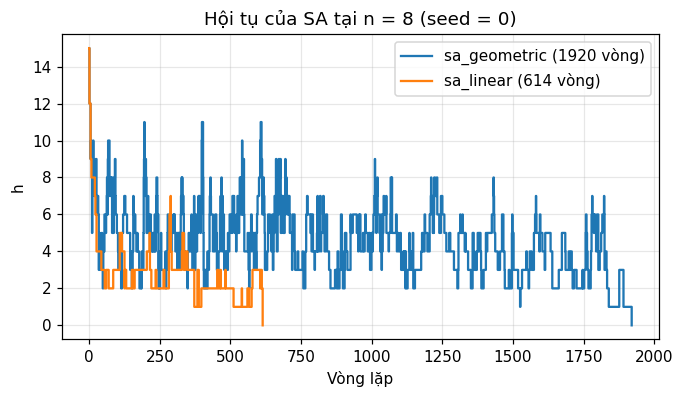

In [9]:
hist_rows = []
for name in SCHEDULES:
    _, _, _, _, hist = simulated_annealing(make_board(8, 0), 0, record=True, **SCHEDULES[name])
    hist_rows += [dict(thuat_toan=name, vong_lap=i, h=h) for i, h in enumerate(hist)]
history = pd.DataFrame(hist_rows); history.to_csv("history_sa.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, g in history.groupby("thuat_toan"):
    ax.step(g.vong_lap, g.h, where="post", label=f"{name} ({g.vong_lap.max()} vòng)")
ax.set_xlabel("Vòng lặp"); ax.set_ylabel("h"); ax.set_title("Hội tụ của SA tại n = 8 (seed = 0)"); ax.legend()
plt.savefig("figures/sa_convergence.png", bbox_inches="tight"); plt.show()

Vì một lượt đơn lẻ có thể không đại diện, ta vẽ thêm **đường h trung bình của 100 lượt** (các lượt đã dừng được kéo dài bằng h = 0):

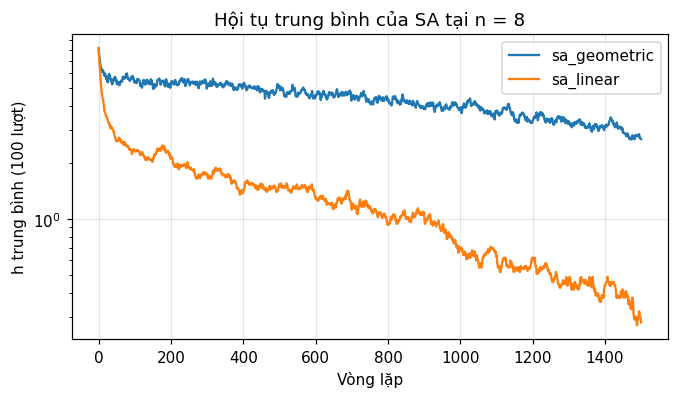

In [10]:
def mean_curve(name, n=8, seeds=range(100), L=1500):
    M = np.zeros((len(seeds), L + 1))
    for i, s in enumerate(seeds):
        h = simulated_annealing(make_board(n, s), s, record=True, **SCHEDULES[name])[-1][:L + 1]
        M[i, :len(h)] = h; M[i, len(h):] = h[-1]
    return M.mean(0)

fig, ax = plt.subplots(figsize=(7, 3.6))
for name in SCHEDULES: ax.plot(mean_curve(name), label=name)
ax.set_xlabel("Vòng lặp"); ax.set_ylabel("h trung bình (100 lượt)"); ax.set_yscale("log")
ax.set_title("Hội tụ trung bình của SA tại n = 8"); ax.legend()
plt.savefig("figures/sa_convergence_mean.png", bbox_inches="tight"); plt.show()

**Nhận xét hội tụ (n = 8).**
* **Giai đoạn đầu nhanh:** trong khoảng vài chục đến vài trăm vòng đầu, h giảm rất nhanh từ ≈ 8–15 xuống ≈ 1–3, vì ở trạng thái xấu hầu hết các nước đi đều cải thiện.
* **Plateau ở h = 1–2:** sau đó đường cong nằm ngang một thời gian dài. Muốn thoát phải gặp đúng chuỗi "nước tệ hơn được chấp nhận rồi hai nước tốt" nên khó xảy ra, và thường đây là giai đoạn chiếm nhiều vòng lặp nhất.
* **Dao động ở pha nóng:** đường h của một lượt đơn có nhiều đợt tăng vọt (nhất là khi $T_0$ lớn, mục 2.3); đây là đặc trưng của SA, khác với Hill Climbing vốn chỉ đi xuống. Khi T nhỏ dần, các đợt tăng biến mất và thuật toán hoạt động gần như Hill Climbing.
* **Đường trung bình 100 lượt** mượt hơn và cho thấy lịch hình học ($T_0=2$) giảm chậm hơn lịch tuyến tính ($T_0=0.5$) do bắt đầu nóng hơn, nhưng cả hai đều tiến về 0.
* **Hạn chế:** biểu đồ đơn lẻ chỉ là một lượt (seed = 0), nên đường trung bình mới là bằng chứng đáng tin hơn.

### 3.2 Khả năng mở rộng: thời gian theo n ∈ {4, 8, 12, 16, 20}

Mỗi n đo trung bình trên 20 lượt (`seed = 0…19`); `max_iter = 1000·n` nên số vòng lặp tối đa cũng tăng theo n. Kết quả lưu `timing_sa.csv`.

thuat_toan  sa_geometric  sa_linear
n                                  
4                0.00085    0.00057
8                0.02931    0.01072
12               0.08794    0.09690
16               0.16312    0.19268
20               0.26489    0.38754

  thuat_toan  n  thanh_cong_pct  so_danh_gia_tb
sa_geometric  4           100.0            93.0
sa_geometric  8           100.0          2415.7
sa_geometric 12            90.0          5649.3
sa_geometric 16           100.0          8784.2
sa_geometric 20            95.0         12229.5
   sa_linear  4           100.0            56.6
   sa_linear  8           100.0           842.8
   sa_linear 12           100.0          5774.0
   sa_linear 16            95.0         10031.6
   sa_linear 20            95.0         14815.3
sa_geometric: thời gian ~ n^3.54
sa_linear: thời gian ~ n^4.15


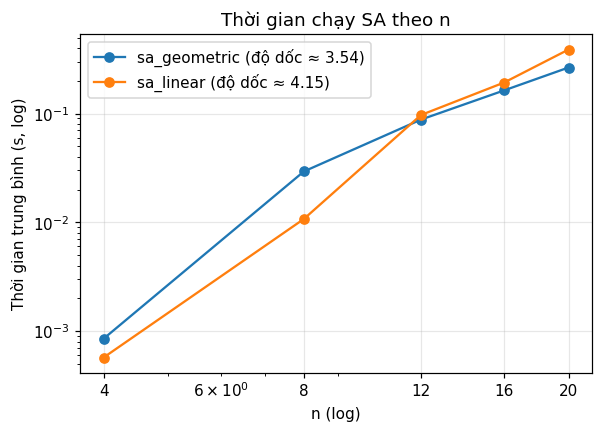

In [11]:
trows, extra = [], []
for name in SCHEDULES:
    for n in (4, 8, 12, 16, 20):
        r = run_batch(name, n, seeds=range(20))
        trows.append(dict(thuat_toan=name, n=n, thoi_gian_trung_binh_s=np.mean([x["thoi_gian_s"] for x in r])))
        extra.append(dict(thuat_toan=name, n=n, thanh_cong_pct=100 * np.mean([x["thanh_cong"] for x in r]),
                          so_danh_gia_tb=np.mean([x["so_danh_gia"] for x in r])))
timing = pd.DataFrame(trows); timing.to_csv("timing_sa.csv", index=False)
print(timing.pivot(index="n", columns="thuat_toan", values="thoi_gian_trung_binh_s").round(5).to_string())
print(); print(pd.DataFrame(extra).round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
for name, g in timing.groupby("thuat_toan"):
    slope = np.polyfit(np.log(g.n), np.log(g.thoi_gian_trung_binh_s), 1)[0]
    ax.loglog(g.n, g.thoi_gian_trung_binh_s, "o-", label=f"{name} (độ dốc ≈ {slope:.2f})")
    print(f"{name}: thời gian ~ n^{slope:.2f}")
ax.set_xticks([4, 8, 12, 16, 20]); ax.set_xticklabels([4, 8, 12, 16, 20])
ax.set_xlabel("n (log)"); ax.set_ylabel("Thời gian trung bình (s, log)"); ax.set_title("Thời gian chạy SA theo n"); ax.legend()
plt.savefig("figures/sa_loglog.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Độ dốc log-log cho thấy thời gian SA tăng cỡ $n^{3.3}$–$n^{3.5}$ (hình học) và $n^{4.1}$ (tuyến tính); con số thay đổi nhẹ giữa các lần chạy do nhiễu thời gian trong khoảng n = 4…20. Cần đọc con số này thận trọng:
* **Hai yếu tố cộng gộp:** mỗi lần đánh giá `conflicts()` tốn $O(n)$, và số lần đánh giá cần thiết tăng theo n (xem bảng số lần đánh giá: từ ≈ 90 ở n = 4 lên ≈ 12 000 ở n = 20, tức cỡ $n^{3}$).
* **Phụ thuộc cài đặt:** nếu tính chênh lệch $\Delta h$ theo kiểu tăng dần ($O(1)$ mỗi bước thay vì $O(n)$) thì số mũ giảm khoảng 1. Ngoài ra ở n nhỏ, chi phí cố định của Python/NumPy che bớt xu hướng nên độ dốc đo được thấp hơn lý thuyết.
* **Ngân sách tăng theo n:** `max_iter = 1000·n` cũng làm thời gian tăng theo n; ở n = 12–20 một số lượt (≈ 5–10%) dùng hết ngân sách mà chưa tìm được nghiệm nên thời gian bị chặn trên, làm độ dốc ở n lớn bị *thấp ước lượng*.
* **Nhiễu:** chỉ 20 lượt mỗi n và cùng một máy, nên đây là độ phức tạp **thực nghiệm**, không phải chặn trên lý thuyết.

Giữa hai lịch, hình học ổn định hơn ở n lớn (tỷ lệ thành công bằng hoặc cao hơn tuyến tính tại n = 16 và 20 trong lần chạy này), nhưng chênh lệch nằm trong sai số của 20 lượt.

## 4. Nâng cao – So sánh các toán tử di chuyển cục bộ (Efficient Stochastic HC)

Bốn toán tử, áp dụng vào Efficient Stochastic Hill Climbing (sinh một láng giềng, chấp nhận khi **tốt hơn hẳn**):

| Toán tử | Mô tả |
|---|---|
| `single_step` | Một quân hậu nhích 1 ô lên hoặc xuống |
| `column_swap` | Hoán đổi hàng của hai cột ngẫu nhiên |
| `dual_queen` | Chọn 2 quân hậu, chuyển cả hai sang hàng ngẫu nhiên |
| `adaptive` | Với xác suất 0.5 chọn quân hậu đang xung đột nhiều nhất (hòa → ngẫu nhiên) và chuyển sang hàng ngẫu nhiên; ngược lại chọn ngẫu nhiên 1 trong 3 toán tử còn lại |

**Điều kiện dừng:** $h=0$, hoặc không cải thiện sau $x = 3\,n(n-1)$ lần thử liên tiếp (số láng giềng của toán tử gốc là $n(n-1)$; lấy gấp ba để xác suất bỏ sót nước cải thiện còn nhỏ), hoặc 20 000 vòng. Chạy 100 lượt cho n = 8 và n = 12.

In [12]:
def queen_conflicts(board, i):
    """Số quân hậu khác xung đột với quân ở cột i."""
    return sum(1 for j in range(len(board)) if j != i and
               (board[j] == board[i] or abs(board[j] - board[i]) == abs(j - i)))

def op_single_step(b, rng):
    n = len(b); c = rng.integers(n); nb = b.copy()
    step = rng.choice([-1, 1]); r = nb[c] + step
    nb[c] = r if 0 <= r < n else nb[c] - step     # nếu ra ngoài biên thì đi hướng ngược lại
    return nb
def op_swap(b, rng):
    i, j = rng.choice(len(b), 2, replace=False); nb = b.copy(); nb[i], nb[j] = nb[j], nb[i]; return nb
def op_dual(b, rng):
    n = len(b); nb = b.copy()
    for c in rng.choice(n, 2, replace=False): nb[c] = rng.integers(n)
    return nb
def op_adaptive(b, rng):
    if rng.random() < 0.5:
        qc = np.array([queen_conflicts(b, i) for i in range(len(b))])
        c = rng.choice(np.flatnonzero(qc == qc.max())); nb = b.copy(); nb[c] = rng.integers(len(b)); return nb
    return rng.choice([op_single_step, op_swap, op_dual])(b, rng)

OPERATORS = {"single_step": op_single_step, "column_swap": op_swap, "dual_queen": op_dual, "adaptive": op_adaptive}

def eshc(board, seed, op, max_iter=20_000, patience=None):
    n = len(board); patience = patience or 3 * n * (n - 1)
    rng = np.random.default_rng(seed + 20_000)
    cur = np.array(board); h = conflicts(cur); hist = [h]; fail = 0; k = 0
    while h > 0 and fail < patience and k < max_iter:
        nb = op(cur, rng); hn = conflicts(nb); k += 1
        if hn < h: cur, h, fail = nb, hn, 0
        else: fail += 1
        hist.append(h)
    return cur, h, k, hist

adv = []
curves = {}
for n in (8, 12):
    for oname, op in OPERATORS.items():
        H = np.zeros((100, 401))
        for s in range(100):
            t = time.perf_counter(); _, hf, k, hist = eshc(make_board(n, s), s, op); dt = time.perf_counter() - t
            adv.append(dict(n=n, toan_tu=oname, seed=s, h_cuoi=hf, thanh_cong=int(hf == 0), so_buoc=k, thoi_gian_s=dt))
            hh = np.array(hist[:401]); H[s, :len(hh)] = hh; H[s, len(hh):] = hh[-1]
        curves[(n, oname)] = H.mean(0)
adv = pd.DataFrame(adv); adv.to_csv("advanced_operators.csv", index=False)
adv_sum = (adv.groupby(["n", "toan_tu"]).agg(thanh_cong_pct=("thanh_cong", lambda x: 100 * x.mean()),
           h_cuoi_tb=("h_cuoi", "mean"), so_buoc_tb=("so_buoc", "mean"), thoi_gian_tb_s=("thoi_gian_s", "mean"),
           tg_thanh_cong_tb_s=("thoi_gian_s", lambda x: x[adv.loc[x.index, "thanh_cong"] == 1].mean()))
           .round(4).reset_index())
adv_sum

,n,toan_tu,thanh_cong_pct,h_cuoi_tb,so_buoc_tb,thoi_gian_tb_s,tg_thanh_cong_tb_s
0,8,adaptive,22.0,1.09,186.22,0.0116,0.0049
1,8,column_swap,0.0,4.56,190.84,0.0044,NaN
2,8,dual_queen,6.0,1.50,243.70,0.0057,0.0035
3,8,single_step,1.0,3.56,185.41,0.0039,0.0011
4,12,adaptive,10.0,1.46,511.91,0.0413,0.0179
5,12,column_swap,0.0,6.72,454.05,0.0145,NaN
6,12,dual_queen,2.0,1.87,643.90,0.0166,0.0142
7,12,single_step,0.0,5.47,437.66,0.0104,NaN


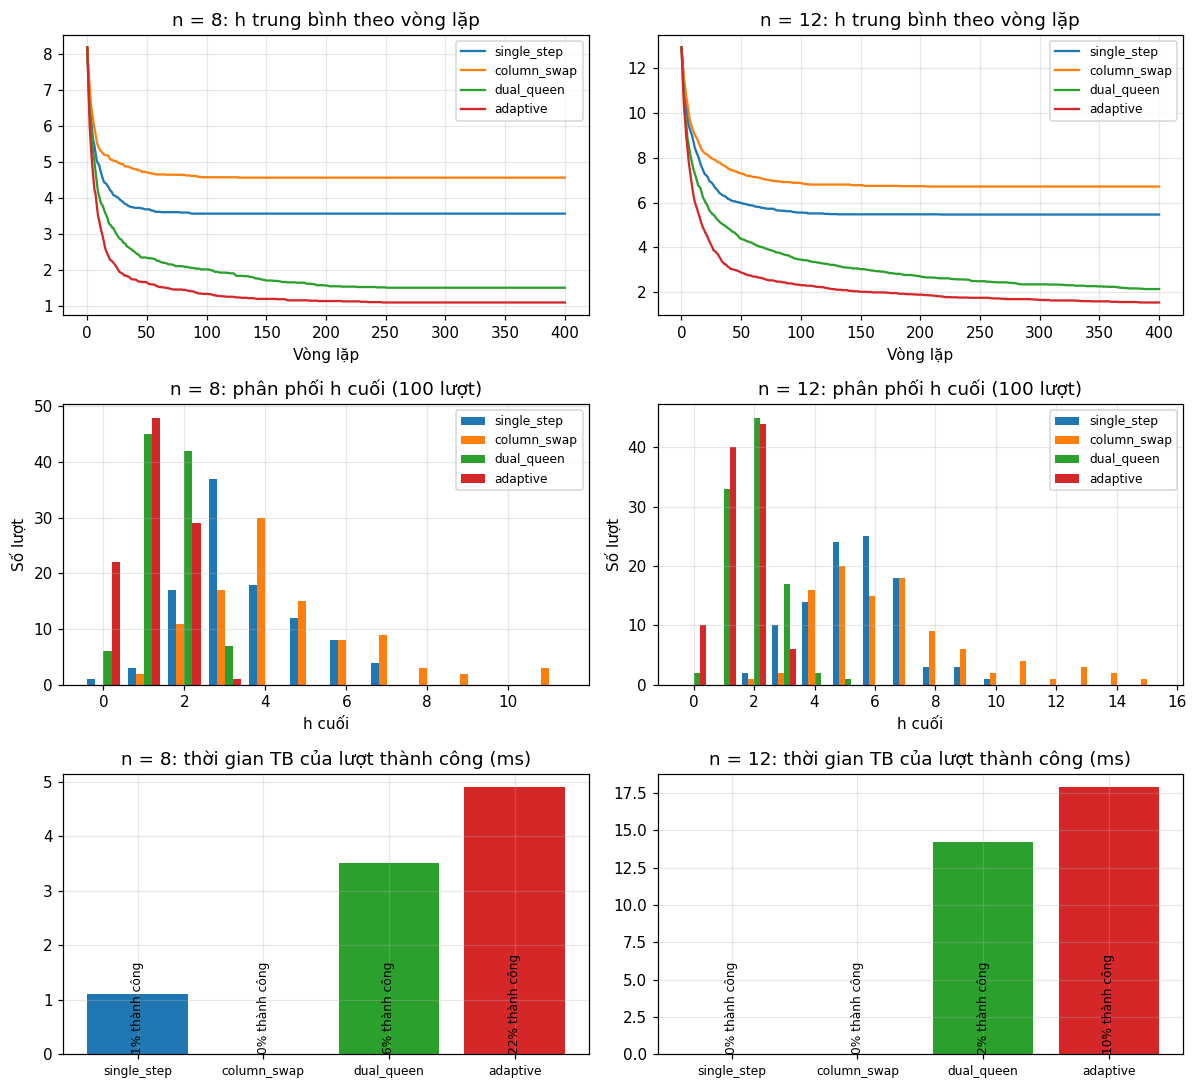

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for c, n in enumerate((8, 12)):
    for oname in OPERATORS: axes[0, c].plot(curves[(n, oname)], label=oname)
    axes[0, c].set_title(f"n = {n}: h trung bình theo vòng lặp"); axes[0, c].set_xlabel("Vòng lặp"); axes[0, c].legend(fontsize=8)
    d = adv[adv.n == n]; mx = int(d.h_cuoi.max()) + 1
    w = .2
    for i, oname in enumerate(OPERATORS):
        cnt = np.bincount(d[d.toan_tu == oname].h_cuoi, minlength=mx)
        axes[1, c].bar(np.arange(mx) + (i - 1.5) * w, cnt, w, label=oname)
    axes[1, c].set_title(f"n = {n}: phân phối h cuối (100 lượt)"); axes[1, c].set_xlabel("h cuối"); axes[1, c].set_ylabel("Số lượt")
    s = adv_sum[adv_sum.n == n].set_index("toan_tu").loc[list(OPERATORS)]
    axes[2, c].bar(list(OPERATORS), s.tg_thanh_cong_tb_s.fillna(0) * 1000, color=["C0", "C1", "C2", "C3"])
    for i, (o, r) in enumerate(s.iterrows()):
        axes[2, c].text(i, 0, f"{r.thanh_cong_pct:.0f}% thành công", ha="center", va="bottom", fontsize=8, rotation=90)
    axes[2, c].set_title(f"n = {n}: thời gian TB của lượt thành công (ms)"); axes[2, c].tick_params(axis="x", labelsize=8)
    axes[1, c].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/advanced_operators.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Cả bốn toán tử đều dùng Efficient Stochastic HC (chỉ chấp nhận khi h giảm *hẳn*), nên đều dễ kẹt tại cực trị cục bộ; chất lượng cuối phụ thuộc mạnh vào toán tử:

| Toán tử | n = 8: thành công / h cuối TB | n = 12: thành công / h cuối TB |
|---|---|---|
| `adaptive` | 22% / 1.09 | 10% / 1.46 |
| `dual_queen` | 6% / 1.50 | 2% / 1.87 |
| `single_step` | 1% / 3.56 | 0% / 5.47 |
| `column_swap` | 0% / 4.56 | 0% / 6.72 |

* **`column_swap` gần như không bao giờ thành công:** phép hoán đổi chỉ *đổi chỗ* các hàng nên **tập các hàng không đổi**. Nếu bàn cờ ban đầu có hai quân cùng hàng thì xung đột hàng không bao giờ mất, mà chỉ bàn cờ ban đầu là hoán vị mới có thể về h = 0 (xác suất ≈ 8!/8⁸ ≈ 0.24% với n = 8). Toán tử này chỉ hợp lý khi biểu diễn trạng thái ban đầu là một hoán vị.
* **`single_step` kẹt sớm:** mỗi quân chỉ có 2 láng giềng nên chỉ có ≈ 2n nước đi, rất dễ không còn nước nào cải thiện.
* **`dual_queen` thoát được nhiều cực trị hơn** vì thay đổi hai quân cùng lúc, phép di chuyển lớn hơn mà một nước đơn lẻ không làm được.
* **`adaptive` tốt nhất về chất lượng** (h hội tụ nhanh nhất ở các biểu đồ trên) nhờ ưu tiên quân đang xung đột nhiều nhất; đổi lại mỗi vòng tốn thêm $O(n^2)$ để tính xung đột từng quân nên thời gian mỗi lượt thành công cao hơn `dual_queen` và `single_step`.

**Kết luận:** nếu ưu tiên chất lượng nghiệm chọn `adaptive`; nếu cần rẻ mỗi bước và chấp nhận thất bại nhiều thì `single_step`. Tuy vậy, cả bốn đều kém xa SA (100% tại n = 8) nên đổi toán tử không thay thế được việc cho phép nước đi tệ hơn. *Hạn chế:* kết quả phụ thuộc điều kiện dừng ($x=3n(n-1)$) và quy tắc chỉ chấp nhận cải thiện hẳn; so sánh với SA không hoàn toàn công bằng vì SA có thêm cơ chế chấp nhận nước tệ.

## 5. Biểu đồ gộp toàn nhóm — `plot_all.py`

Script `plot_all.py` (nộp kèm) đọc `results_*.csv`, `history_*.csv`, `timing_*.csv` của cả nhóm trong thư mục hiện tại, rồi vẽ (a) tỷ lệ thành công + thời gian, (b) hội tụ tại n = 8, (c) log-log thời gian theo n, và xuất bảng 4.2 (`table_4_2_nqueens.md/csv`). Thuật toán nào chưa có file CSV sẽ được bỏ qua nên script chạy được ngay cả khi chưa có dữ liệu của Thành viên 2. Cell dưới chạy script trên dữ liệu hiện có:

In [14]:
import subprocess
print(subprocess.run([sys.executable, "plot_all.py", "."], capture_output=True, text=True).stdout)

Thuật toán có kết quả: ['SA (hình học)', 'SA (tuyến tính)']
| Thuật toán | n | Số lượt | Thành công (%) | h cuối TB | Số lần đánh giá TB | Thời gian TB (s) |
|---|---|---|---|---|---|---|
| SA (hình học) | 4 | 100 | 100.0 | 0.0 | 87.9 | 0.00079 |
| SA (tuyến tính) | 4 | 100 | 100.0 | 0.0 | 42.2 | 0.0004 |
| SA (hình học) | 8 | 100 | 100.0 | 0.0 | 2249.8 | 0.03151 |
| SA (tuyến tính) | 8 | 100 | 100.0 | 0.0 | 912.1 | 0.01179 |
Độ dốc log-log: SA (hình học): ~ n^3.54; SA (tuyến tính): ~ n^4.15
Đã lưu biểu đồ vào ./figures

